<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/statistical_physics/statphys_visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Statistical Physics* — `statphys_visualizations.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Statistical Physics — Core Visualizations
**Chapters 1–5 companion notebook**

| # | Visualization | Chapter |
|---|---|---|
| 1 | Two-state system: Entropy $S(E)$ and Schottky anomaly $C(T)$ | Ch 1 §1.2 |
| 2 | Canonical ensemble: Partition function, energy & fluctuations | Ch 1 §1.3 |
| 3 | Maxwell speed distribution $f(v,T)$ | Ch 2 §2.3 |
| 4 | Planck distribution & Stefan-Boltzmann: blackbody radiation | Ch 3 §3.2 |
| 5 | Heat capacity of solids: Dulong-Petit → Einstein → Debye | Ch 3 §3.3 |
| 6 | Quantum statistics: Fermi-Dirac vs Bose-Einstein vs Boltzmann | Ch 3 §3.5–3.6 |
| 7 | Ising mean-field: magnetisation $m(T)$ and Landau free energy | Ch 5 §5.2–5.4 |

---
Run each section independently. All imports are at the top of each cell.

In [1]:
# ── Shared imports (run this first) ──────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize
import matplotlib.cm as cm
from scipy.optimize import brentq
from scipy.special import zeta

plt.rcParams.update({
    'figure.facecolor': '#0d1117',
    'axes.facecolor':   '#161b22',
    'axes.edgecolor':   '#30363d',
    'axes.labelcolor':  '#c9d1d9',
    'axes.titlecolor':  '#f0f6fc',
    'xtick.color':      '#8b949e',
    'ytick.color':      '#8b949e',
    'text.color':       '#c9d1d9',
    'grid.color':       '#21262d',
    'grid.linestyle':   '--',
    'grid.linewidth':   0.6,
    'legend.facecolor': '#161b22',
    'legend.edgecolor': '#30363d',
    'font.size':        11,
    'axes.titlesize':   13,
    'axes.labelsize':   11,
})

CH_COLORS = {
    1: '#f0b84a',  # Ch 1 fundamentals — amber
    2: '#4ecba8',  # Ch 2 classical gas — teal
    3: '#7fa8f0',  # Ch 3 quantum gas — periwinkle
    4: '#e07fa0',  # Ch 4 thermodynamics — rose
    5: '#a87de8',  # Ch 5 phase transitions — violet
}

print('Setup complete — ready to run visualizations.')

Setup complete — ready to run visualizations.


---
## Visualization 1 — Two-State System: Entropy and Schottky Anomaly
**Ch 1 §1.2.3 & §1.2.2**

A system of $N$ independent spins, each with energies $E_\downarrow=0$, $E_\uparrow=\epsilon$.

$$S(E) = -k_B N\left[\frac{E}{N\epsilon}\ln\frac{E}{N\epsilon} + \left(1-\frac{E}{N\epsilon}\right)\ln\left(1-\frac{E}{N\epsilon}\right)\right]$$

$$C(T) = Nk_B\left(\frac{\epsilon}{k_BT}\right)^2 \frac{e^{\epsilon/k_BT}}{(e^{\epsilon/k_BT}+1)^2}$$

**Key physics:** $S$ has a maximum at $E = N\epsilon/2$ (infinite temperature). $C(T)$ peaks near $T\sim\epsilon/k_B$ — the **Schottky anomaly**.

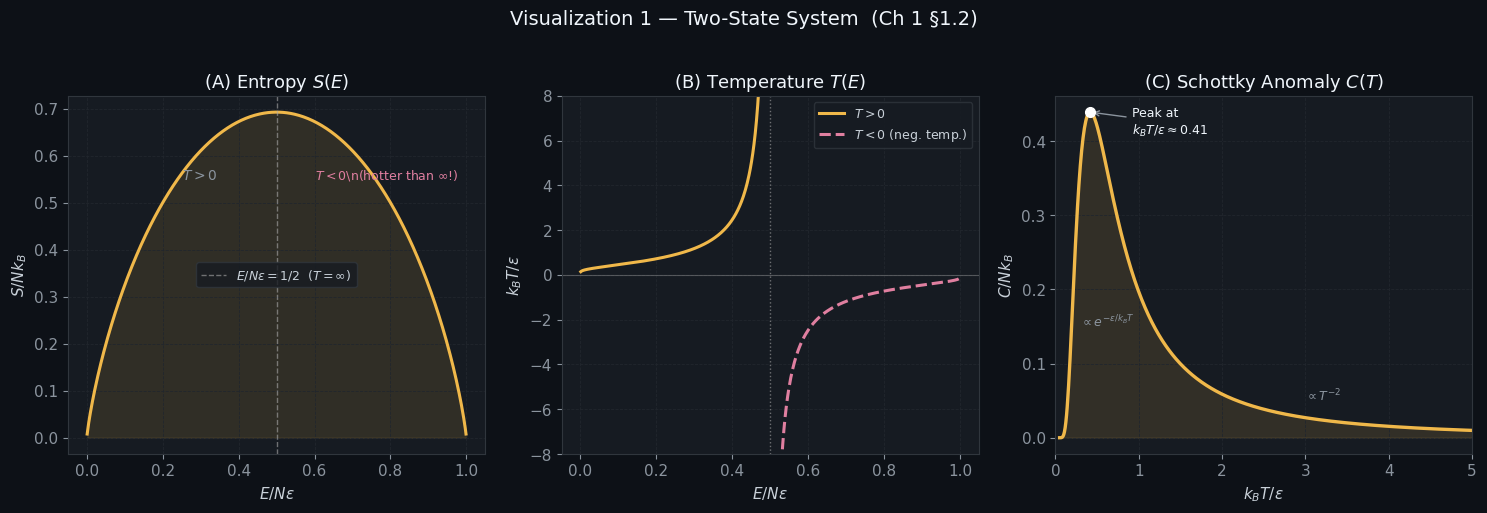

Key points:
  S_max = Nk_B ln 2 = 0.6931 Nk_B  (at E = Nε/2, T = ∞)
  C peak at k_BT/ε ≈ 0.414
  C peak value ≈ 0.4392 Nk_B


In [2]:
# ── Viz 1: Two-State System ───────────────────────────────────────────────────
kB = 1.0   # natural units: kB = 1, epsilon = 1
eps = 1.0

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Visualization 1 — Two-State System  (Ch 1 §1.2)',
             fontsize=14, color='#f0f6fc', y=1.02)

col = CH_COLORS[1]

# ── Panel A: S(E) ──────────────────────────────────────────────────────────────
ax = axes[0]
x = np.linspace(0.001, 0.999, 500)   # x = E/Nε
S = -(x * np.log(x) + (1-x) * np.log(1-x))  # S/NkB

ax.plot(x, S, color=col, lw=2.2)
ax.axvline(0.5, color='#aaa', lw=1, ls='--', alpha=0.6, label=r'$E/N\epsilon = 1/2$  ($T=\infty$)')
ax.fill_between(x, S, alpha=0.12, color=col)
ax.set_xlabel(r'$E / N\epsilon$')
ax.set_ylabel(r'$S / Nk_B$')
ax.set_title(r'(A) Entropy $S(E)$')
ax.legend(fontsize=9)
ax.grid(True)
# annotate regions
ax.annotate(r'$T>0$', xy=(0.25, 0.55), fontsize=10, color='#8b949e')
ax.annotate(r'$T<0$\n(hotter than $\infty$!)', xy=(0.6, 0.55), fontsize=9, color='#e07fa0')

# ── Panel B: T(E) and β(E) ────────────────────────────────────────────────────
ax = axes[1]
# 1/T = dS/dE = (kB/ε) ln((N-N↑)/N↑)
# T = ε/kB / ln((1-x)/x)
x2 = np.linspace(0.001, 0.49, 300)
T_pos = eps / (kB * np.log((1-x2)/x2))
x3 = np.linspace(0.51, 0.999, 300)
T_neg = eps / (kB * np.log((1-x3)/x3))  # negative T

ax.plot(x2, T_pos, color=col, lw=2.2, label=r'$T > 0$')
ax.plot(x3, T_neg, color='#e07fa0', lw=2.2, ls='--', label=r'$T < 0$ (neg. temp.)')
ax.axvline(0.5, color='#aaa', lw=1, ls=':', alpha=0.6)
ax.axhline(0,   color='#aaa', lw=0.8, alpha=0.4)
ax.set_ylim(-8, 8)
ax.set_xlabel(r'$E / N\epsilon$')
ax.set_ylabel(r'$k_BT / \epsilon$')
ax.set_title(r'(B) Temperature $T(E)$')
ax.legend(fontsize=9)
ax.grid(True)

# ── Panel C: Schottky heat capacity C(T) ─────────────────────────────────────
ax = axes[2]
T = np.linspace(0.05, 5.0, 600)
beta = 1.0 / (kB * T)
C = kB * (beta * eps)**2 * np.exp(beta * eps) / (np.exp(beta * eps) + 1)**2

ax.plot(T, C, color=col, lw=2.4)
ax.fill_between(T, C, alpha=0.13, color=col)

# mark peak
T_peak = T[np.argmax(C)]
C_peak = np.max(C)
ax.plot(T_peak, C_peak, 'o', color='#fff', ms=7, zorder=5)
ax.annotate(f'Peak at\n$k_BT/\\epsilon \\approx {T_peak:.2f}$',
            xy=(T_peak, C_peak), xytext=(T_peak+0.5, C_peak-0.03),
            fontsize=9, color='#f0f6fc',
            arrowprops=dict(arrowstyle='->', color='#8b949e', lw=1))

# asymptotic labels
ax.text(0.3, 0.15, r'$\propto e^{-\epsilon/k_BT}$', fontsize=9, color='#8b949e')
ax.text(3.0, 0.05, r'$\propto T^{-2}$', fontsize=9, color='#8b949e')

ax.set_xlabel(r'$k_BT / \epsilon$')
ax.set_ylabel(r'$C / Nk_B$')
ax.set_title(r'(C) Schottky Anomaly $C(T)$')
ax.set_xlim(0, 5)
ax.grid(True)

plt.tight_layout()
plt.savefig('viz1_two_state.png', dpi=150, bbox_inches='tight')
plt.show()
print('Key points:')
print(f'  S_max = Nk_B ln 2 = {np.log(2):.4f} Nk_B  (at E = Nε/2, T = ∞)')
print(f'  C peak at k_BT/ε ≈ {T_peak:.3f}')
print(f'  C peak value ≈ {C_peak:.4f} Nk_B')

---
## Visualization 2 — Canonical Ensemble: Partition Function and Fluctuations
**Ch 1 §1.3.1–1.3.2**

For the $N$-spin two-state system in the canonical ensemble:

$$Z = (1 + e^{-\beta\epsilon})^N, \qquad \langle E\rangle = -\frac{\partial\ln Z}{\partial\beta}, \qquad (\Delta E)^2 = k_BT^2 C_V$$

**Key physics:** The fluctuation-dissipation relation $(\Delta E)^2 = k_BT^2 C_V$ links microscopic fluctuations to the macroscopic heat capacity. Relative fluctuations $\Delta E/\langle E\rangle \sim 1/\sqrt{N} \to 0$.

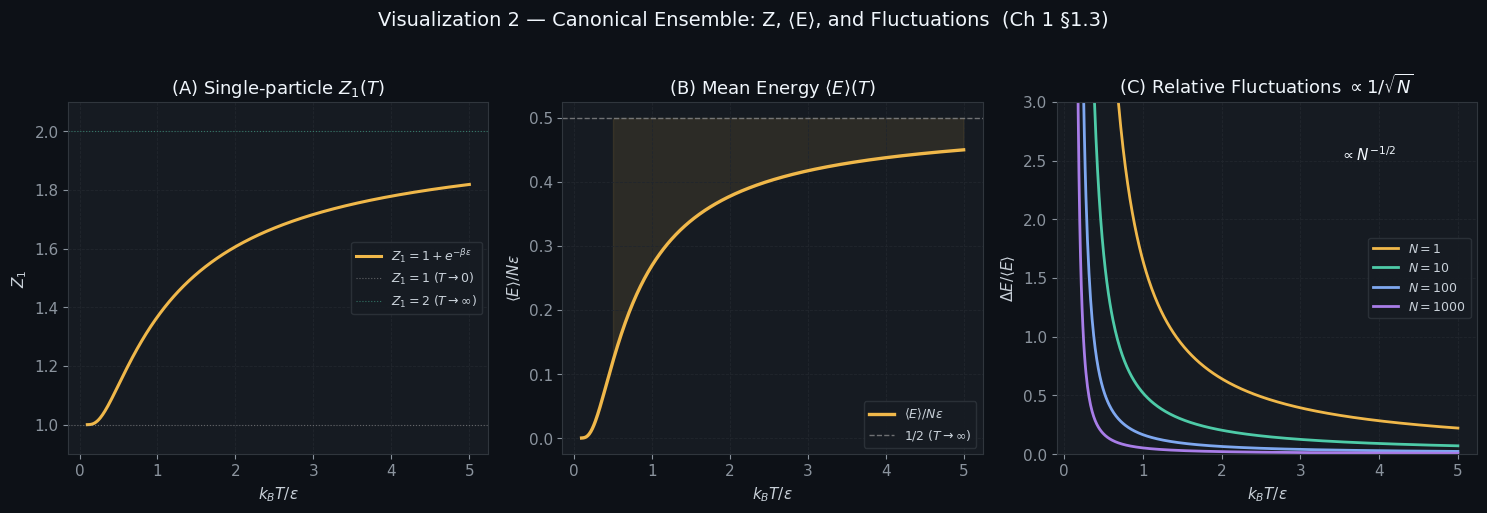

In [3]:
# ── Viz 2: Canonical Ensemble ─────────────────────────────────────────────────
kB = 1.0; eps = 1.0
col = CH_COLORS[1]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Visualization 2 — Canonical Ensemble: Z, ⟨E⟩, and Fluctuations  (Ch 1 §1.3)',
             fontsize=14, color='#f0f6fc', y=1.02)

T = np.linspace(0.1, 5.0, 500)
beta = 1.0 / T
N_vals = [1, 10, 100, 1000]
colors_N = ['#f0b84a', '#4ecba8', '#7fa8f0', '#a87de8']

# ── Panel A: Z_1(β) and log Z_1 ───────────────────────────────────────────────
ax = axes[0]
Z1 = 1 + np.exp(-beta * eps)
ax.plot(T, Z1, color=col, lw=2.2, label=r'$Z_1 = 1 + e^{-\beta\epsilon}$')
ax.axhline(1.0, color='#aaa', lw=0.8, ls=':', alpha=0.5, label=r'$Z_1 = 1$ ($T\to 0$)')
ax.axhline(2.0, color='#4ecba8', lw=0.8, ls=':', alpha=0.5, label=r'$Z_1 = 2$ ($T\to\infty$)')
ax.set_xlabel(r'$k_BT/\epsilon$')
ax.set_ylabel(r'$Z_1$')
ax.set_title(r'(A) Single-particle $Z_1(T)$')
ax.legend(fontsize=9)
ax.grid(True)
ax.set_ylim(0.9, 2.1)

# ── Panel B: ⟨E⟩/Nε vs T ─────────────────────────────────────────────────────
ax = axes[1]
E_mean = eps / (np.exp(beta * eps) + 1)   # per particle
ax.plot(T, E_mean, color=col, lw=2.4, label=r'$\langle E\rangle/N\epsilon$')
ax.axhline(0.5, color='#aaa', lw=1, ls='--', alpha=0.6, label=r'$1/2$ ($T\to\infty$)')
ax.fill_between(T, E_mean, 0.5, where=T>0.5, alpha=0.1, color=col)
ax.set_xlabel(r'$k_BT/\epsilon$')
ax.set_ylabel(r'$\langle E \rangle / N\epsilon$')
ax.set_title(r'(B) Mean Energy $\langle E\rangle(T)$')
ax.legend(fontsize=9)
ax.grid(True)

# ── Panel C: Relative fluctuations ΔE/<E> for different N ────────────────────
ax = axes[2]
# (ΔE)^2 = kBT^2 C_V = N * kB * (eps/kBT)^2 * exp(eps/kBT)/(exp(eps/kBT)+1)^2
C_per_particle = (beta*eps)**2 * np.exp(beta*eps) / (np.exp(beta*eps)+1)**2

for N, c in zip(N_vals, colors_N):
    var_E = N * C_per_particle   # (ΔE)^2 / (kB T)^2  ... actually (ΔE/kBT)^2 * kBT^2
    # ΔE / <E> = sqrt(N * C_per_particle * kBT^2) / (N * E_mean)
    #          = sqrt(C_per_particle) / (sqrt(N) * E_mean)
    with np.errstate(divide='ignore', invalid='ignore'):
        rel_fluct = np.sqrt(C_per_particle) / (np.sqrt(N) * E_mean)
        rel_fluct = np.where(E_mean > 0.001, rel_fluct, np.nan)
    ax.plot(T, rel_fluct, color=c, lw=2, label=f'$N = {N}$')

ax.set_xlabel(r'$k_BT/\epsilon$')
ax.set_ylabel(r'$\Delta E / \langle E \rangle$')
ax.set_title(r'(C) Relative Fluctuations $\propto 1/\sqrt{N}$')
ax.legend(fontsize=9)
ax.grid(True)
ax.set_ylim(0, 3)
ax.text(3.5, 2.5, r'$\propto N^{-1/2}$', fontsize=11, color='#f0f6fc')

plt.tight_layout()
plt.savefig('viz2_canonical.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Visualization 3 — Maxwell Speed Distribution
**Ch 2 §2.3**

$$f(v) = 4\pi\left(\frac{m}{2\pi k_BT}\right)^{3/2} v^2\, e^{-mv^2/2k_BT}$$

Three characteristic speeds:
$v_\text{mp} = \sqrt{2k_BT/m}$, $\quad\langle v\rangle = \sqrt{8k_BT/\pi m}$, $\quad v_\text{rms} = \sqrt{3k_BT/m}$

**Key physics:** The $v^2$ phase-space factor pushes the peak away from zero. At higher $T$ the distribution broadens and flattens, with all characteristic speeds $\propto \sqrt{T}$.

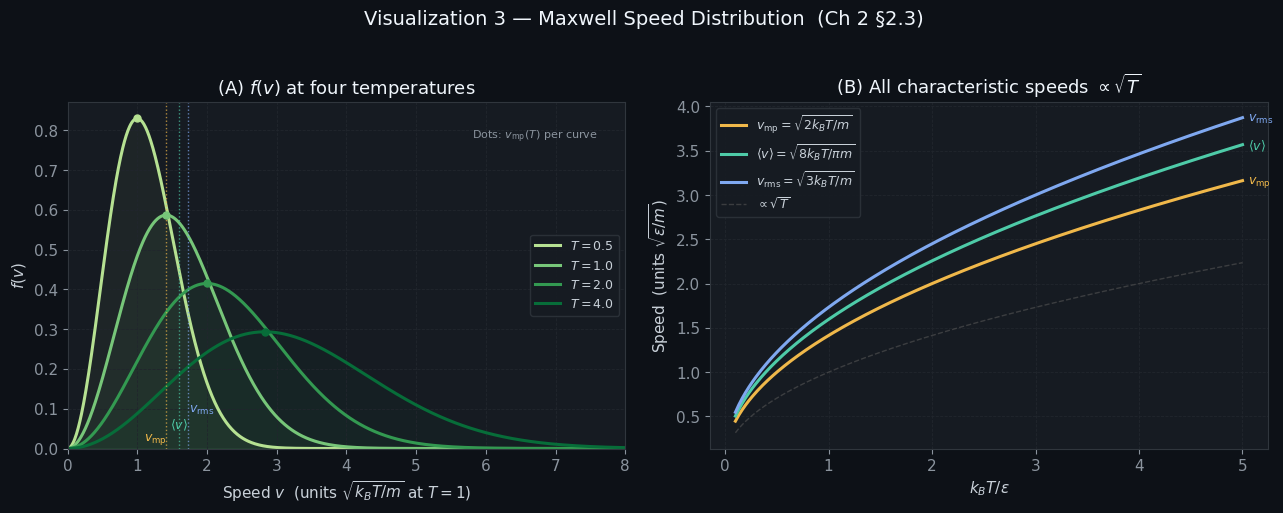

v_mp : <v> : v_rms = 1 : 1.1284 : 1.2247


In [4]:
# ── Viz 3: Maxwell Speed Distribution ────────────────────────────────────────
col = CH_COLORS[2]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Visualization 3 — Maxwell Speed Distribution  (Ch 2 §2.3)',
             fontsize=14, color='#f0f6fc', y=1.02)

m = 1.0; kB = 1.0
T_list = [0.5, 1.0, 2.0, 4.0]
T_colors = [plt.cm.YlGn(v) for v in [0.35, 0.50, 0.68, 0.85]]

# ── Panel A: f(v) with per-curve v_mp dots ───────────────────────────────────
ax = axes[0]
v = np.linspace(0, 8.0, 1000)

for T_val, tc in zip(T_list, T_colors):
    A = 4 * np.pi * (m / (2 * np.pi * kB * T_val))**1.5
    fv = A * v**2 * np.exp(-m * v**2 / (2 * kB * T_val))
    ax.plot(v, fv, color=tc, lw=2.2, label=f'$T = {T_val}$')
    ax.fill_between(v, fv, alpha=0.05, color=tc)
    vmp_T = np.sqrt(2 * kB * T_val / m)
    fmp_T = A * vmp_T**2 * np.exp(-m * vmp_T**2 / (2 * kB * T_val))
    ax.plot(vmp_T, fmp_T, 'o', color=tc, ms=5, zorder=5)

# annotate v_mp, <v>, v_rms at T=1 only
T1 = 1.0
A1 = 4 * np.pi * (m / (2 * np.pi * kB * T1))**1.5
vmp1  = np.sqrt(2 * kB * T1 / m)
vavg1 = np.sqrt(8 * kB * T1 / (np.pi * m))
vrms1 = np.sqrt(3 * kB * T1 / m)
for xx, yy, vv, lbl, lc in [(vmp1-0.15, 0.02, vmp1,  r'$v_\mathrm{mp}$',    '#f0b84a'),
                    (vavg1, 0.05, vavg1, r'$\langle v\rangle$', '#4ecba8'),
                    (vrms1+0.2, 0.09, vrms1, r'$v_\mathrm{rms}$',   '#7fa8f0')]:
    ax.axvline(vv, color=lc, lw=1.0, ls=':', alpha=0.7)
    #f1 = A1 * vv**2 * np.exp(-m * vv**2 / (2 * kB * T1))
    #ax.annotate(lbl, xy=(vv, f1 + 0.04), ha='center', fontsize=9, color=lc)
    ax.annotate(lbl, xy=(xx, yy), ha='center', fontsize=9, color=lc)

ax.text(5.8, 0.78, r'Dots: $v_\mathrm{mp}(T)$ per curve', fontsize=8, color='#8b949e')
ax.set_xlabel(r'Speed $v$  (units $\sqrt{k_BT/m}$ at $T=1$)')
ax.set_ylabel(r'$f(v)$')
ax.set_title(r'(A) $f(v)$ at four temperatures')
ax.legend(fontsize=9)
ax.set_xlim(0, 8.0); ax.set_ylim(0)
ax.grid(True)

# ── Panel B: Characteristic speeds vs T ──────────────────────────────────────
ax = axes[1]
T_arr = np.linspace(0.1, 5.0, 300)
vmp_arr  = np.sqrt(2 * kB * T_arr / m)
vavg_arr = np.sqrt(8 * kB * T_arr / (np.pi * m))
vrms_arr = np.sqrt(3 * kB * T_arr / m)

ax.plot(T_arr, vmp_arr,  color='#f0b84a', lw=2.2, label=r'$v_\mathrm{mp} = \sqrt{2k_BT/m}$')
ax.plot(T_arr, vavg_arr, color='#4ecba8', lw=2.2, label=r'$\langle v\rangle = \sqrt{8k_BT/\pi m}$')
ax.plot(T_arr, vrms_arr, color='#7fa8f0', lw=2.2, label=r'$v_\mathrm{rms} = \sqrt{3k_BT/m}$')
ax.plot(T_arr, np.sqrt(T_arr), color='#555', lw=1.0, ls='--', alpha=0.6, label=r'$\propto\sqrt{T}$')
ax.set_xlabel(r'$k_BT/\epsilon$')
ax.set_ylabel(r'Speed  (units $\sqrt{\epsilon/m}$)')
ax.set_title(r'(B) All characteristic speeds $\propto \sqrt{T}$')
ax.legend(fontsize=9)
ax.grid(True)
for arr, lbl, lc in [(vrms_arr, r'$v_\mathrm{rms}$', '#7fa8f0'),
                     (vavg_arr, r'$\langle v\rangle$','#4ecba8'),
                     (vmp_arr,  r'$v_\mathrm{mp}$',   '#f0b84a')]:
    ax.text(5.05, arr[-1] - 0.01, lbl, color=lc, fontsize=9, va='center')

plt.tight_layout()
plt.savefig('viz3_maxwell.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'v_mp : <v> : v_rms = 1 : {np.sqrt(4/np.pi):.4f} : {np.sqrt(3/2):.4f}')


---
## Visualization 4 — Planck Distribution and Blackbody Radiation
**Ch 3 §3.2**

Energy density per unit frequency:
$$u(\omega) = \frac{\hbar}{\pi^2 c^3}\cdot\frac{\omega^3}{e^{\hbar\omega/k_BT}-1}$$

- **Wien's displacement law:** $\omega_\text{max} = \zeta\, k_BT/\hbar$, $\zeta\approx 2.822$
- **Stefan-Boltzmann:** $u_\text{tot} = \frac{\pi^2 k_B^4}{15\hbar^3 c^3}T^4$
- **Classical limit:** Rayleigh-Jeans $u\propto\omega^2 k_BT$ (no $\hbar$, diverges at high $\omega$)

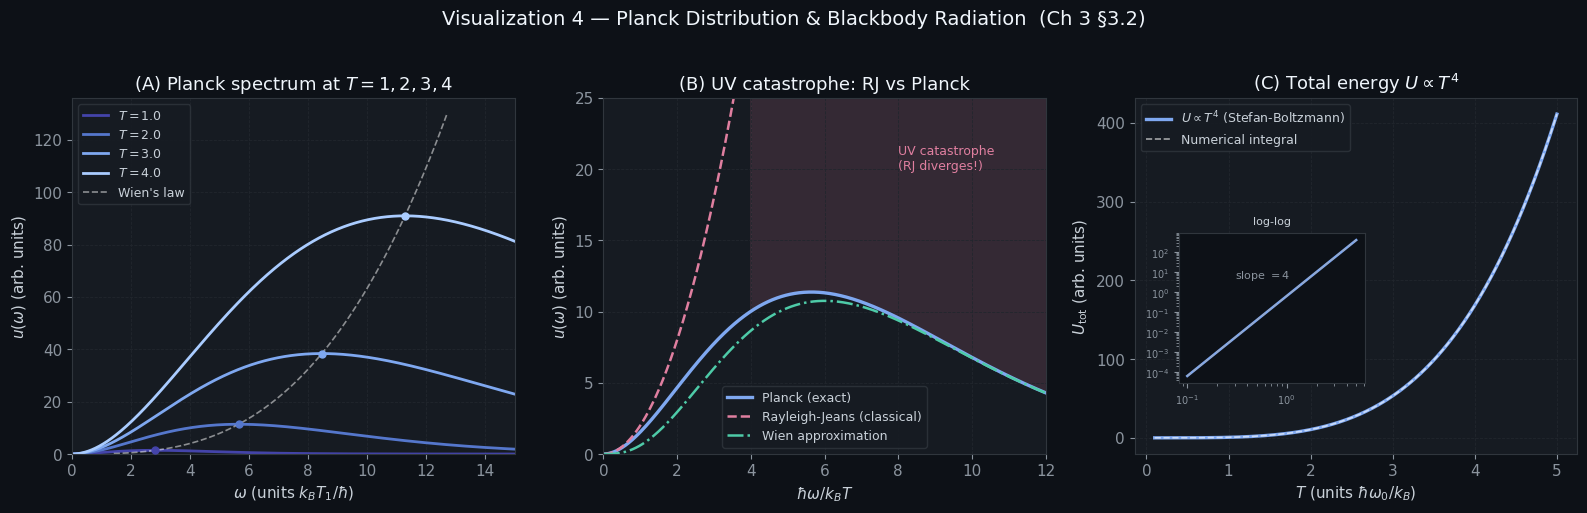

Stefan-Boltzmann constant (natural units): π²/15 = 0.6579736267392905


In [5]:
# ── Viz 4: Planck Distribution ────────────────────────────────────────────────
col = CH_COLORS[3]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Visualization 4 — Planck Distribution & Blackbody Radiation  (Ch 3 §3.2)',
             fontsize=14, color='#f0f6fc', y=1.02)

# Natural units: ħ = kB = c = 1
# u(ω) = ω³/(π²) * 1/(e^(ω/T) − 1)  [setting ħ=kB=c=1]

omega = np.linspace(0.01, 15, 1000)
T_list = [1.0, 2.0, 3.0, 4.0]
colors_T = ['#4444aa', '#5577cc', '#7fa8f0', '#aaccff']

# ── Panel A: Planck distributions at multiple T ───────────────────────────────
ax = axes[0]
for T_val, tc in zip(T_list, colors_T):
    with np.errstate(over='ignore'):
        u = omega**3 / (np.exp(omega / T_val) - 1)
    u = np.where(np.isfinite(u), u, 0)
    ax.plot(omega, u, color=tc, lw=2.0, label=f'$T = {T_val}$')

# Wien's displacement
zeta_wien = 2.8214
for T_val, tc in zip(T_list, colors_T):
    omega_max = zeta_wien * T_val
    u_max = omega_max**3 / (np.exp(omega_max / T_val) - 1)
    ax.plot(omega_max, u_max, 'o', color=tc, ms=5, zorder=5)

# Wien displacement law curve
T_arr = np.linspace(0.5, 4.5, 100)
ax.plot(zeta_wien * T_arr,
        (zeta_wien*T_arr)**3 / (np.exp(zeta_wien) - 1),
        color='#fff', lw=1.2, ls='--', alpha=0.5, label=r"Wien's law")

ax.set_xlabel(r'$\omega$ (units $k_BT_1/\hbar$)')
ax.set_ylabel(r'$u(\omega)$ (arb. units)')
ax.set_title(r'(A) Planck spectrum at $T=1,2,3,4$')
ax.legend(fontsize=9)
ax.set_xlim(0, 15)
ax.set_ylim(0)
ax.grid(True)

# ── Panel B: Planck vs Rayleigh-Jeans vs Wien approximation (single T) ────────
ax = axes[1]
T_ref = 2.0
with np.errstate(over='ignore'):
    u_planck = omega**3 / (np.exp(omega / T_ref) - 1)
u_planck = np.where(np.isfinite(u_planck), u_planck, 0)
u_RJ    = omega**2 * T_ref           # Rayleigh-Jeans: classical limit
u_Wien  = omega**3 * np.exp(-omega / T_ref)  # Wien approximation

ax.plot(omega, u_planck, color='#7fa8f0', lw=2.4, label='Planck (exact)')
ax.plot(omega, u_RJ,    color='#e07fa0', lw=1.8, ls='--', label='Rayleigh-Jeans (classical)')
ax.plot(omega, u_Wien,  color='#4ecba8', lw=1.8, ls='-.', label='Wien approximation')

ax.set_xlim(0, 12)
ax.set_ylim(0, 25)
ax.set_xlabel(r'$\hbar\omega / k_BT$')
ax.set_ylabel(r'$u(\omega)$ (arb. units)')
ax.set_title(r'(B) UV catastrophe: RJ vs Planck')
ax.legend(fontsize=9)
ax.fill_between(omega, u_RJ, u_planck,
                where=omega>2*T_ref, alpha=0.15, color='#e07fa0',
                label='RJ excess (UV catastrophe)')
ax.text(8, 20, 'UV catastrophe\n(RJ diverges!)', color='#e07fa0', fontsize=9)
ax.grid(True)

# ── Panel C: Stefan-Boltzmann U_tot ∝ T^4 ────────────────────────────────────
ax = axes[2]
T_sb = np.linspace(0.1, 5.0, 300)

# numerical integration of Planck spectrum = π²/15 T^4 (natural units)
from scipy.integrate import quad
def planck_integral(T_val):
    def integrand(x):
        if x < 1e-10: return 0
        ex = np.exp(x)
        if not np.isfinite(ex): return 0
        return x**3 / (ex - 1)
    result, _ = quad(integrand, 0, 200)
    return result * T_val**4 / np.pi**2

U_numerical = np.array([planck_integral(T_val) for T_val in T_sb])
U_SB        = np.pi**2 / 15 * T_sb**4   # analytic: ∫x³/(e^x-1)dx = π⁴/15

ax.plot(T_sb, U_SB, color=col, lw=2.4, label=r'$U \propto T^4$ (Stefan-Boltzmann)')
ax.plot(T_sb, U_numerical, color='#fff', lw=1.2, ls='--', alpha=0.6, label='Numerical integral')

# log-log inset
axin = ax.inset_axes([0.1, 0.2, 0.42, 0.42])
axin.set_facecolor('#0d1117')
axin.loglog(T_sb, U_SB, color=col, lw=1.8)
axin.loglog(T_sb, T_sb**4 * 0.66, color='#aaa', lw=1, ls='--', alpha=0.6)
axin.text(0.3, 5, r'slope $= 4$', color='#8b949e', fontsize=8)
axin.set_title('log-log', fontsize=8, color='#c9d1d9')
axin.tick_params(labelsize=7)
for spine in axin.spines.values():
    spine.set_color('#30363d')

ax.set_xlabel(r'$T$ (units $\hbar\omega_0/k_B$)')
ax.set_ylabel(r'$U_{\rm tot}$ (arb. units)')
ax.set_title(r'(C) Total energy $U \propto T^4$')
ax.legend(fontsize=9)
ax.grid(True)

plt.tight_layout()
plt.savefig('viz4_planck.png', dpi=150, bbox_inches='tight')
plt.show()

print("Stefan-Boltzmann constant (natural units): π²/15 =", np.pi**2/15)

---
## Visualization 5 — Heat Capacity of Solids: Dulong-Petit → Einstein → Debye
**Ch 3 §3.3**

| Model | $C_V(T\to 0)$ | $C_V(T\to\infty)$ |
|---|---|---|
| Classical (Dulong-Petit) | $3Nk_B$ | $3Nk_B$ |
| Einstein | $\propto e^{-\Theta_E/T}$ (exponential) | $3Nk_B$ |
| Debye | $\propto T^3$ (correct!) | $3Nk_B$ |

$$C_V^{\rm Debye} = 9Nk_B\left(\frac{T}{T_D}\right)^3\int_0^{T_D/T}\frac{x^4 e^x}{(e^x-1)^2}\,dx$$

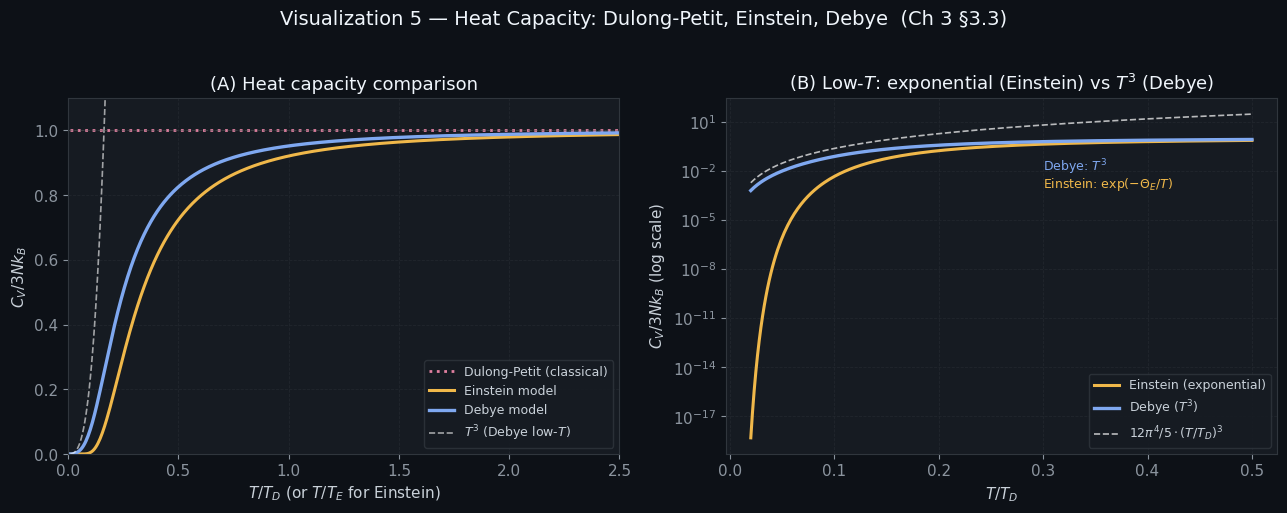

Debye T³ coefficient: 12π⁴/5 = 233.7818


In [6]:
# ── Viz 5: Heat Capacity of Solids ───────────────────────────────────────────
from scipy.integrate import quad
col = CH_COLORS[3]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Visualization 5 — Heat Capacity: Dulong-Petit, Einstein, Debye  (Ch 3 §3.3)',
             fontsize=14, color='#f0f6fc', y=1.02)

T_norm = np.linspace(0.01, 2.5, 500)   # T/T_D or T/T_E

# ── Dulong-Petit (classical) ──────────────────────────────────────────────────
C_classical = np.ones_like(T_norm)   # C = 3NkB, normalised to 1

# ── Einstein model ────────────────────────────────────────────────────────────
# C_E = 3NkB (Θ_E/T)^2 exp(Θ_E/T) / (exp(Θ_E/T)-1)^2
# Normalised: C/3NkB
def C_einstein(t_ratio):   # t_ratio = T/T_E
    x = 1.0 / t_ratio
    with np.errstate(over='ignore'):
        ex = np.exp(x)
    if not np.isfinite(ex): return 0.0
    return x**2 * ex / (ex - 1)**2

C_E = np.array([C_einstein(t) for t in T_norm])

# ── Debye model ───────────────────────────────────────────────────────────────
def C_debye_single(t_ratio):   # t_ratio = T/T_D
    x_max = 1.0 / t_ratio
    def integrand(x):
        with np.errstate(over='ignore'):
            ex = np.exp(x)
        if not np.isfinite(ex): return 0.0
        return x**4 * ex / (ex - 1)**2
    I, _ = quad(integrand, 1e-8, x_max)
    return 3 * t_ratio**3 * I

C_D = np.array([C_debye_single(t) for t in T_norm])

# ── Panel A: C_V(T) comparison ────────────────────────────────────────────────
ax = axes[0]
ax.plot(T_norm, C_classical, color='#e07fa0', lw=2.0, ls=':', label='Dulong-Petit (classical)')
ax.plot(T_norm, C_E, color='#f0b84a', lw=2.2, label='Einstein model')
ax.plot(T_norm, C_D, color=col, lw=2.4, label='Debye model')

# T^3 guide for Debye
mask = T_norm < 0.3
ax.plot(T_norm[mask], 12*np.pi**4/5 * T_norm[mask]**3,
        color='#fff', lw=1.2, ls='--', alpha=0.6, label=r'$T^3$ (Debye low-$T$)')

ax.axhline(1.0, color='#555', lw=0.8, ls='--', alpha=0.5)
ax.set_xlabel(r'$T / T_{D}$ (or $T/T_E$ for Einstein)')
ax.set_ylabel(r'$C_V / 3Nk_B$')
ax.set_title(r'(A) Heat capacity comparison')
ax.legend(fontsize=9)
ax.grid(True)
ax.set_xlim(0, 2.5)
ax.set_ylim(0, 1.1)

# ── Panel B: Low-T region — Einstein exponential vs Debye T^3 ─────────────────
ax = axes[1]
T_low = np.linspace(0.02, 0.5, 300)

C_E_low = np.array([C_einstein(t) for t in T_low])
C_D_low = np.array([C_debye_single(t) for t in T_low])

ax.semilogy(T_low, C_E_low, color='#f0b84a', lw=2.2, label='Einstein (exponential)')
ax.semilogy(T_low, C_D_low, color=col, lw=2.4, label='Debye ($T^3$)')
ax.semilogy(T_low, 12*np.pi**4/5*T_low**3, color='#fff', lw=1.2, ls='--',
            alpha=0.7, label=r'$12\pi^4/5 \cdot (T/T_D)^3$')

ax.set_xlabel(r'$T / T_D$')
ax.set_ylabel(r'$C_V / 3Nk_B$ (log scale)')
ax.set_title(r'(B) Low-$T$: exponential (Einstein) vs $T^3$ (Debye)')
ax.legend(fontsize=9)
ax.grid(True)
ax.text(0.3, 1e-3, 'Einstein: $\\exp(-\\Theta_E/T)$', color='#f0b84a', fontsize=9)
ax.text(0.3, 1e-2, 'Debye: $T^3$', color=col, fontsize=9)

plt.tight_layout()
plt.savefig('viz5_heat_capacity.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Debye T³ coefficient: 12π⁴/5 = {12*np.pi**4/5:.4f}')

---
## Visualization 6 — Quantum Statistics: FD vs BE vs Boltzmann
**Ch 3 §3.5–3.6**

$$\langle n(E)\rangle = \frac{1}{e^{(E-\mu)/k_BT} \mp 1} \quad\begin{cases} - & \text{Bose-Einstein}\\+ & \text{Fermi-Dirac}\end{cases}$$

**Key physics:** At high $T$ (or low density, $e^{\beta\mu}\ll 1$), both distributions → classical Boltzmann. At low $T$: FD fills up sharply to $E_F$; BE macroscopically occupies the ground state (BEC).

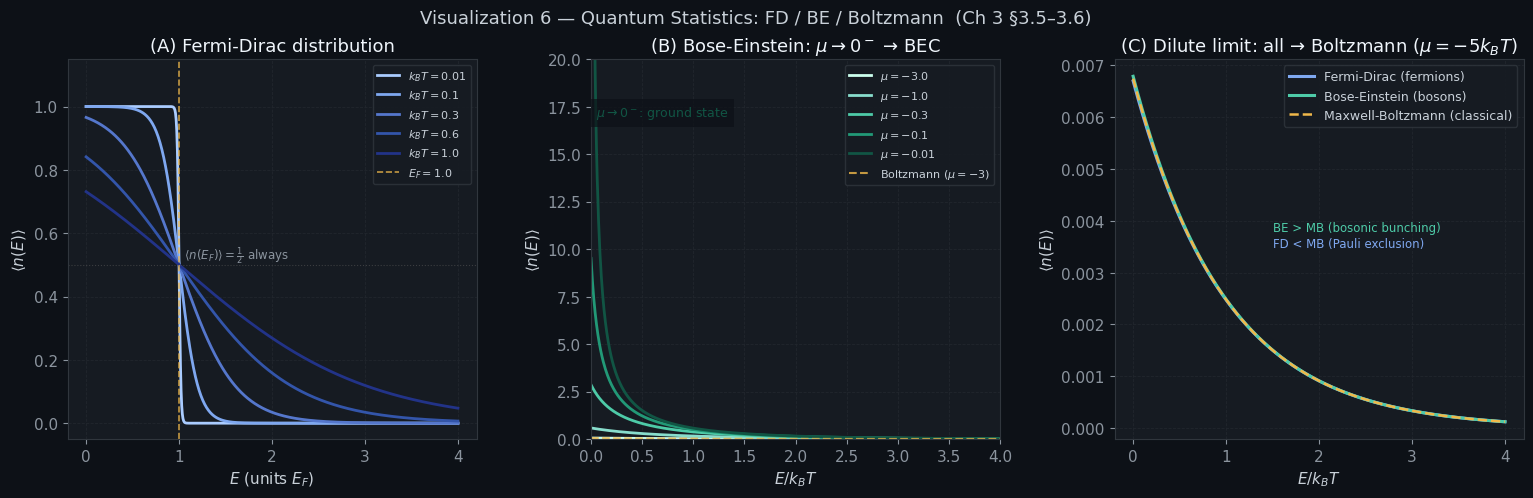

In [7]:
# ── Viz 6: Quantum Statistics ─────────────────────────────────────────────────
col3 = CH_COLORS[3]


fig, axes = plt.subplots(1, 3, figsize=(16, 5))

fig.suptitle('Visualization 6 — Quantum Statistics: FD / BE / Boltzmann  (Ch 3 §3.5–3.6)',
    fontsize=13)

fig.subplots_adjust(
    left=0.07,
    right=0.98,
    bottom=0.12,
    top=0.88,
    wspace=0.28
)


E = np.linspace(0, 4, 600)

# ── Panel A: FD distribution at multiple T (fixed μ = E_F = 1) ───────────────
ax = axes[0]
mu_FD = 1.0
T_list_FD = [0.01, 0.1, 0.3, 0.6, 1.0]
colors_FD = ['#aaccff', '#7fa8f0', '#5577cc', '#3355aa', '#223388']

for T_val, tc in zip(T_list_FD, colors_FD):
    with np.errstate(over='ignore'):
        nFD = 1.0 / (np.exp((E - mu_FD) / T_val) + 1)
    ax.plot(E, nFD, color=tc, lw=2.0, label=f'$k_BT = {T_val}$')

ax.axvline(mu_FD, color='#f0b84a', lw=1.2, ls='--', alpha=0.8, label=f'$E_F = {mu_FD}$')
ax.axhline(0.5, color='#555', lw=0.8, ls=':', alpha=0.6)
ax.text(1.05, 0.52, r'$\langle n(E_F)\rangle = \frac{1}{2}$ always', fontsize=8.5, color='#8b949e')

ax.set_xlabel(r'$E$ (units $E_F$)')
ax.set_ylabel(r'$\langle n(E) \rangle$')
ax.set_title(r'(A) Fermi-Dirac distribution')
ax.legend(fontsize=8, loc='upper right')
ax.grid(True)
ax.set_ylim(-0.05, 1.15)

# ── Panel B: BE distribution (μ < 0, varying) ────────────────────────────────
ax = axes[1]
T_BE = 1.0
mu_list = [-3.0, -1.0, -0.3, -0.1, -0.01]
colors_mu = ['#ccffee', '#88ddcc', '#4ecba8', '#229977', '#115544']

for mu_val, mc in zip(mu_list, colors_mu):
    with np.errstate(over='ignore', invalid='ignore'):
        nBE = 1.0 / (np.exp((E - mu_val) / T_BE) - 1)
    nBE = np.where((nBE > 0) & np.isfinite(nBE), nBE, np.nan)
    ax.plot(E, nBE, color=mc, lw=2.0, label=f'$\\mu = {mu_val}$')

# classical Boltzmann
nBoltz = np.exp(-(E - mu_list[0]) / T_BE)
ax.plot(E, nBoltz, color='#f0b84a', lw=1.5, ls='--', alpha=0.8, label='Boltzmann ($\\mu=-3$)')

ax.set_xlabel(r'$E / k_BT$')
ax.set_ylabel(r'$\langle n(E) \rangle$')
ax.set_title(r'(B) Bose-Einstein: $\mu \to 0^-$ → BEC')
ax.legend(fontsize=8)
ax.set_ylim(0, 20)
ax.set_xlim(0, 4)
ax.grid(True)
ax.text(0.05, 17, r'$\mu\to 0^-$: ground state', color='#115544', fontsize=9,
        bbox=dict(facecolor='#0d1117', alpha=0.7, edgecolor='none'))

# ── Panel C: Comparison at same T (dilute limit: classical convergence) ────────
ax = axes[2]
T_comp = 1.0
mu_comp = -5.0   # dilute: e^(βμ) << 1
z = np.exp(mu_comp / T_comp)   # fugacity

with np.errstate(over='ignore', invalid='ignore'):
    nFD_comp   = 1.0 / (np.exp((E - mu_comp) / T_comp) + 1)
    nBE_comp   = 1.0 / (np.exp((E - mu_comp) / T_comp) - 1)
nBE_comp = np.where(nBE_comp > 0, nBE_comp, np.nan)
nMB_comp   = z * np.exp(-E / T_comp)   # Maxwell-Boltzmann

ax.plot(E, nFD_comp, color='#7fa8f0', lw=2.2, label='Fermi-Dirac (fermions)')
ax.plot(E, nBE_comp, color='#4ecba8', lw=2.2, label='Bose-Einstein (bosons)')
ax.plot(E, nMB_comp, color='#f0b84a', lw=1.8, ls='--', label='Maxwell-Boltzmann (classical)')

ax.set_xlabel(r'$E / k_BT$')
ax.set_ylabel(r'$\langle n(E) \rangle$')
ax.set_title(r'(C) Dilute limit: all → Boltzmann ($\mu = -5k_BT$)')
ax.legend(fontsize=9)
ax.grid(True)
ax.text(1.5, 0.0035, 'FD < MB (Pauli exclusion)', color='#7fa8f0', fontsize=8.5)
ax.text(1.5, 0.0038, 'BE > MB (bosonic bunching)', color='#4ecba8', fontsize=8.5)

plt.savefig('viz6_quantum_stats.png', dpi=300, bbox_inches='tight')
plt.show()

---
## Visualization 7 — Ising Mean-Field & Landau Theory
**Ch 5 §5.2–5.4**

Mean-field self-consistency equation:
$$m = \tanh\!\left(\frac{Jqm + B}{k_BT}\right)$$

Landau free energy (expanded near $T_c$):
$$F(T;m) = F_0 + a(T)m^2 + b(T)m^4 + \cdots, \quad a(T) = a_0(T-T_c)$$

**Key physics:** $T_c = Jq/k_B$. Below $T_c$: two minima at $m = \pm m_0(T)$ — spontaneous symmetry breaking. Mean-field exponent: $m_0 \propto (T_c - T)^{1/2}$.

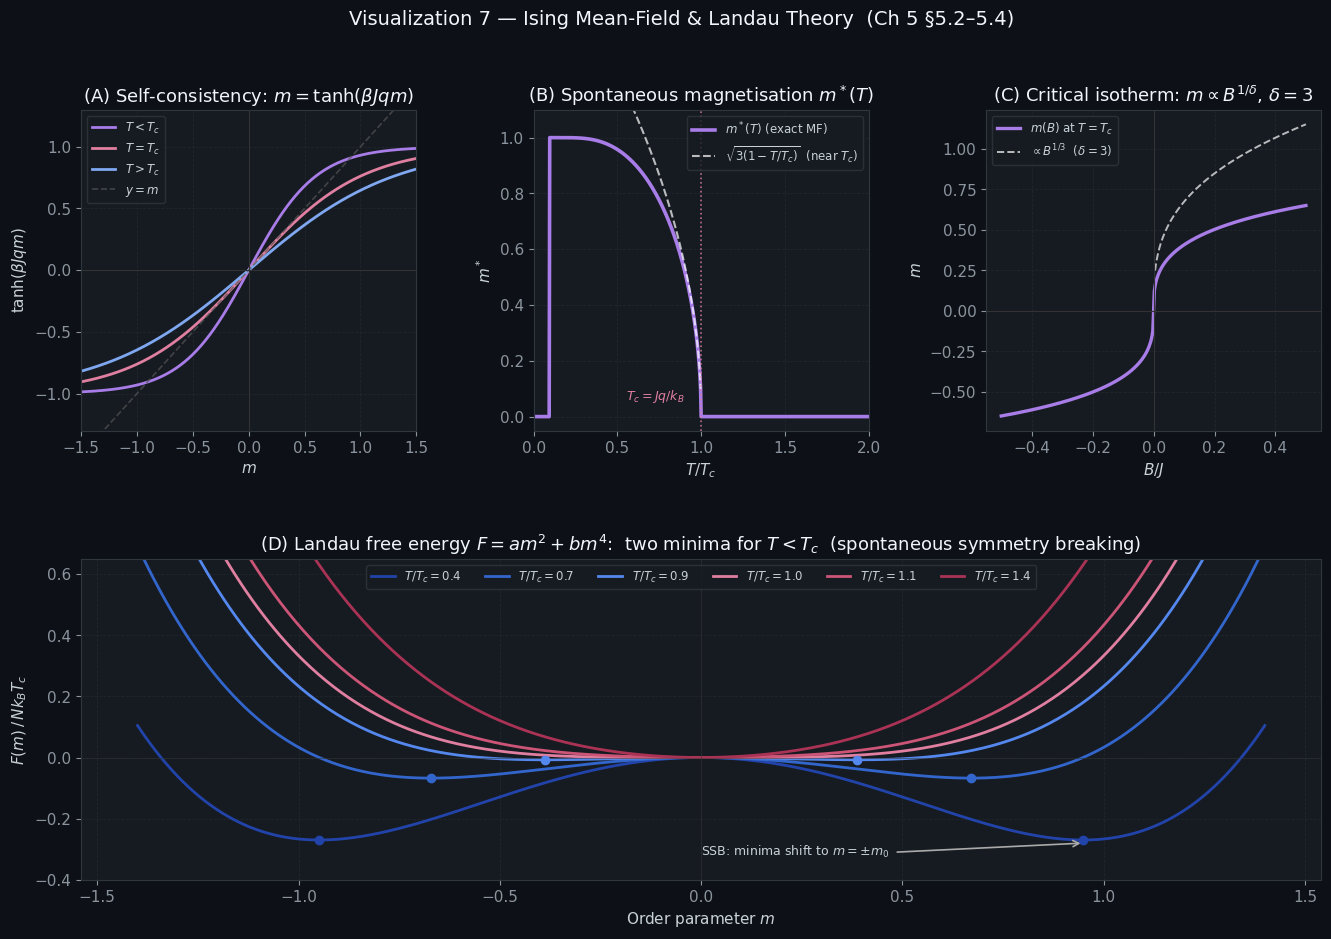

T_c = 4.0,  beta = 1/2,  delta = 3


In [8]:
# ── Viz 7: Ising Mean-Field and Landau Theory ─────────────────────────────────
from scipy.optimize import brentq
col = CH_COLORS[5]

fig = plt.figure(figsize=(16, 10))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.40, wspace=0.35)
fig.suptitle('Visualization 7 — Ising Mean-Field & Landau Theory  (Ch 5 §5.2–5.4)',
             fontsize=14, color='#f0f6fc')

kB = 1.0; J = 1.0; q = 4
Tc = J * q / kB   # = 4.0

# ── Panel A: graphical self-consistency ──────────────────────────────────────
ax = fig.add_subplot(gs[0, 0])
m_arr = np.linspace(-1.5, 1.5, 400)
for T_val, tc, lbl in [(0.6*Tc, '#a87de8', r'$T < T_c$'),
                        (Tc,     '#e07fa0', r'$T = T_c$'),
                        (1.3*Tc, '#7fa8f0', r'$T > T_c$')]:
    ax.plot(m_arr, np.tanh(J*q*m_arr/(kB*T_val)), color=tc, lw=2.0, label=lbl)
ax.plot(m_arr, m_arr, color='#555', lw=1.2, ls='--', alpha=0.7, label=r'$y = m$')
ax.set_xlabel(r'$m$'); ax.set_ylabel(r'$\tanh(\beta Jqm)$')
ax.set_title(r'(A) Self-consistency: $m = \tanh(\beta Jqm)$')
ax.legend(fontsize=8.5)
ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.3, 1.3)
ax.axhline(0, color='#333', lw=0.8); ax.axvline(0, color='#333', lw=0.8)
ax.grid(True)

# ── Panel B: robust m*(T) via brentq ─────────────────────────────────────────
ax = fig.add_subplot(gs[0, 1])
T_range = np.linspace(0.01*Tc, 2.0*Tc, 600)
m_star = np.zeros_like(T_range)
for i, T_val in enumerate(T_range):
    if T_val >= Tc:
        m_star[i] = 0.0
    else:
        try:
            m_star[i] = brentq(lambda m: m - np.tanh(J*q*m/(kB*T_val)), 1e-9, 1.0-1e-9)
        except ValueError:
            m_star[i] = 0.0

# MF approximation: m ~ sqrt(3) * sqrt(1 - T/Tc) near Tc
T_below = T_range[T_range < Tc]
m_mf = np.sqrt(3.0 * np.maximum(0.0, (Tc - T_below) / Tc))

ax.plot(T_range/Tc, m_star, color=col, lw=2.6, label=r'$m^*(T)$ (exact MF)')
ax.plot(T_below/Tc, m_mf,   color='#fff', lw=1.5, ls='--', alpha=0.7,
        label=r'$\sqrt{3(1-T/T_c)}$  (near $T_c$)')
ax.axvline(1.0, color='#e07fa0', lw=1.2, ls=':', alpha=0.8)
ax.text(0.55, 0.06, r'$T_c = Jq/k_B$', color='#e07fa0', fontsize=9)
ax.set_xlabel(r'$T/T_c$'); ax.set_ylabel(r'$m^*$')
ax.set_title(r'(B) Spontaneous magnetisation $m^*(T)$')
ax.legend(fontsize=8.5)
ax.grid(True)
ax.set_xlim(0, 2.0); ax.set_ylim(-0.05, 1.1)

# ── Panel C: critical isotherm m(B) ──────────────────────────────────────────
ax = fig.add_subplot(gs[0, 2])
B_arr = np.linspace(-0.5, 0.5, 401)
m_crit = np.zeros_like(B_arr)
for i, B_val in enumerate(B_arr):
    if abs(B_val) < 1e-8:
        m_crit[i] = 0.0
        continue
    lo = -1.0+1e-9 if B_val < 0 else 1e-9
    hi =  -1e-9    if B_val < 0 else 1.0-1e-9
    try:
        m_crit[i] = brentq(lambda m: m - np.tanh((J*q*m + B_val)/(kB*Tc)), lo, hi)
    except:
        m_crit[i] = np.sign(B_val) * abs(B_val)**(1.0/3.0) * 0.5

B_pos = B_arr[B_arr > 0.005]
ax.plot(B_arr, m_crit, color=col, lw=2.4, label=r'$m(B)$ at $T = T_c$')
ax.plot(B_pos, 1.45*B_pos**(1.0/3.0), color='#fff', lw=1.4, ls='--', alpha=0.7,
        label=r'$\propto B^{1/3}$  ($\delta = 3$)')
ax.axhline(0, color='#333', lw=0.8); ax.axvline(0, color='#333', lw=0.8)
ax.set_xlabel(r'$B/J$'); ax.set_ylabel(r'$m$')
ax.set_title(r'(C) Critical isotherm: $m \propto B^{1/\delta}$, $\delta = 3$')
ax.legend(fontsize=8.5); ax.grid(True)

# ── Panel D: Landau free energy F(m) ─────────────────────────────────────────
ax = fig.add_subplot(gs[1, :])
m_L = np.linspace(-1.4, 1.4, 600)
T_L_vals   = [0.4*Tc, 0.7*Tc, 0.9*Tc, Tc, 1.1*Tc, 1.4*Tc]
T_L_colors = ['#2244aa', '#3366cc', '#5588ee', '#e07fa0', '#cc5577', '#aa3355']
b = 1.0 / 3.0
for T_val, tc in zip(T_L_vals, T_L_colors):
    a = (T_val - Tc) / Tc
    F = a * m_L**2 + b * m_L**4
    ax.plot(m_L, F, color=tc, lw=2.0, label=f'$T/T_c = {T_val/Tc:.1f}$')
    if T_val < Tc:
        m_min = np.sqrt(-a / (2*b))
        F_min = a * m_min**2 + b * m_min**4
        ax.plot([m_min, -m_min], [F_min, F_min], 'o', color=tc, ms=6, zorder=5)
ax.axhline(0, color='#333', lw=0.8, alpha=0.5)
ax.axvline(0, color='#333', lw=0.8, alpha=0.5)
ax.set_ylim(-0.40, 0.65)
ax.set_xlabel(r'Order parameter $m$')
ax.set_ylabel(r'$F(m)\,/\,Nk_BT_c$')
ax.set_title(r'(D) Landau free energy $F = am^2 + bm^4$:  two minima for $T < T_c$  (spontaneous symmetry breaking)')
ax.legend(fontsize=8.5, ncol=6, loc='upper center'); ax.grid(True)
ax.annotate('', xy=(0.95, -0.28), xytext=(0.48, -0.31),
            arrowprops=dict(arrowstyle='->', color='#aaa', lw=1.2))
ax.text(0.0, -0.32, r'SSB: minima shift to $m = \pm m_0$', fontsize=9, color='#c9d1d9')

plt.savefig('viz7_ising_landau.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'T_c = {Tc},  beta = 1/2,  delta = 3')


---
## Summary: Key Formulas

| # | System | Central Formula | Chapter |
|---|---|---|---|
| 1 | Two-state system | $S = k_B\log\Omega$, $C \propto e^{-\epsilon/k_BT}/T^2$ | Ch 1 |
| 2 | Canonical ensemble | $Z = \sum e^{-\beta E_n}$, $(\Delta E)^2 = k_BT^2 C_V$ | Ch 1 |
| 3 | Maxwell distribution | $f(v)\propto v^2 e^{-mv^2/2k_BT}$ | Ch 2 |
| 4 | Blackbody radiation | $u(\omega)\propto \omega^3/(e^{\beta\hbar\omega}-1)$, $U\propto T^4$ | Ch 3 |
| 5 | Solids | Debye: $C_V\propto T^3$; Einstein: $\propto e^{-\Theta_E/T}$ | Ch 3 |
| 6 | Quantum gases | $\langle n\rangle = 1/(e^{\beta(E-\mu)}\mp 1)$ | Ch 3 |
| 7 | Phase transitions | $m=\tanh(\beta Jqm)$, $F = am^2+bm^4$ | Ch 5 |